# Quarter-square identity & the geometric mean theorem

Start with a number n, split it into two positive parts a + b = n, and multiply. For n=7: (1,6)->6, (2,5)->10, (3,4)->12.

**Identity:** ab = (n/2)^2 - ((a-b)/2)^2 -- a direct corollary of difference-of-squares (A^2-B^2 = (A-B)(A+B), with A=(a+b)/2, B=(a-b)/2).

**Geometric picture:** draw a semicircle of diameter n. Any point on the arc drops a perpendicular to the diameter, splitting it into a and b=n-a. The right-triangle altitude theorem (Euclid VI.8, the "geometric mean theorem") says that perpendicular's height is exactly sqrt(ab). So the whole grid of products is a semicircle, sampled at integer points -- the max (the most even split) sits at the top.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def check_quarter_square_identity(n_max=50, trials=500):
    rng = np.random.default_rng(0)
    for _ in range(trials):
        n = rng.integers(2, n_max)
        a = rng.integers(1, n)
        b = n - a
        lhs = a * b
        rhs = (n / 2) ** 2 - ((a - b) / 2) ** 2
        assert abs(lhs - rhs) < 1e-9, (n, a, b, lhs, rhs)

def check_geometric_mean_theorem(n=7, samples=1000):
    # point on semicircle of radius n/2 centered at (n/2, 0)
    thetas = np.linspace(0.01, np.pi - 0.01, samples)
    r = n / 2
    x = r + r * np.cos(thetas)   # foot of the perpendicular on the diameter
    y = r * np.sin(thetas)       # perpendicular's height
    a, b = x, n - x
    assert np.allclose(y ** 2, a * b, atol=1e-9)

check_quarter_square_identity()
check_geometric_mean_theorem()
print("identity + geometric mean theorem verified")

identity + geometric mean theorem verified


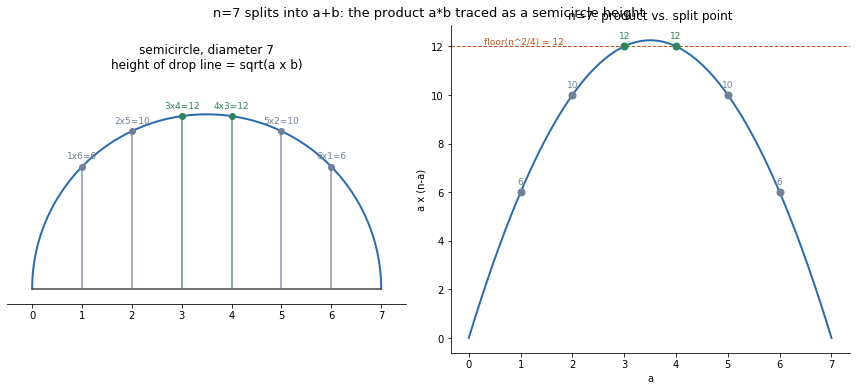

In [2]:
n = 7
splits = [(a, n - a) for a in range(1, n)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

# --- left: semicircle, drop lines = sqrt(product) ---
ax = axes[0]
theta = np.linspace(0, np.pi, 400)
r = n / 2
cx = n / 2
ax.plot(cx + r * np.cos(theta), r * np.sin(theta), color="#2b6cb0", lw=2)
ax.plot([0, n], [0, 0], color="#444444", lw=1.5)

for a, b in splits:
    x, y = a, np.sqrt(a * b)
    even = (a == n - a) or (a, b) in [(3, 4), (4, 3)]
    color = "#2f855a" if even else "#718096"
    ax.plot([x, x], [0, y], color=color, lw=1.5, alpha=0.85)
    ax.plot([x], [y], "o", color=color, ms=6)
    ax.annotate(f"{a}x{b}={a*b}", (x, y), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9, color=color)

ax.set_aspect("equal")
ax.set_xlim(-0.5, n + 0.5)
ax.set_ylim(-0.3, r + 0.8)
ax.set_title(f"semicircle, diameter {n}\nheight of drop line = sqrt(a x b)")
ax.set_xticks(range(n + 1))
ax.set_yticks([])
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)

# --- right: the parabola the products trace ---
ax = axes[1]
a_cont = np.linspace(0, n, 300)
ax.plot(a_cont, a_cont * (n - a_cont), color="#2b6cb0", lw=2)
for a, b in splits:
    color = "#2f855a" if a in (3, 4) else "#718096"
    ax.plot(a, a * b, "o", color=color, ms=7, zorder=3)
    ax.annotate(str(a * b), (a, a * b), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9, color=color)

peak = int(np.floor((n / 2) ** 2))
ax.axhline(peak, color="#c05621", lw=1, ls="--")
ax.annotate(f"floor(n^2/4) = {peak}", (0.3, peak), va="bottom",
            fontsize=9, color="#c05621")
ax.set_xlabel("a")
ax.set_ylabel("a x (n-a)")
ax.set_title(f"n={n}: product vs. split point")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

fig.suptitle(f"n={n} splits into a+b: the product a*b traced as a semicircle height", fontsize=13)
fig.tight_layout()
fig.savefig("quarter_square_semicircle.png", dpi=150)
plt.show()

The peak value floor(n^2/4) is OEIS [A002620](https://oeis.org/A002620) ("quarter-squares"): 0, 1, 2, 4, 6, 9, 12, 16, 20, 25, ... It also has a name in graph theory -- see `mantel_turan_graphs.ipynb` for the combinatorial reading of the same peak.